In [23]:
from pathlib import Path 
import cv2 
import numpy as np 
import matplotlib.pyplot as plt

folder = Path("fotograflar")
fotograflar = {
    "normal": folder / "normal.jpg",
    "golge": folder / "golge.jpg",
    "lamba": folder / "lamba.jpg",
}

for kosul, yol in fotograflar.items():
    print(kosul, yol.is_file())

normal True
golge True
lamba True


## Görüntünün sayısal yapısı ve piksel değerleri
Deney öncesi tahminim: Sarı kaidenin üç noktasında normal ışıkta kırmızı ve yeşilin maviden yüksek olmasını gölgede ise özellikle kırmızı ve yeşilin düşmesini bekliyorum. Gölgede kaideye daha az ışık geldiği için bu değerlerin düşeceğini düşünüyorum.

Boyut (height, width, channels): (1600, 1200, 3)
Veri tipi: uint8
Gozlemlenen deger araligi: 0 ile 255


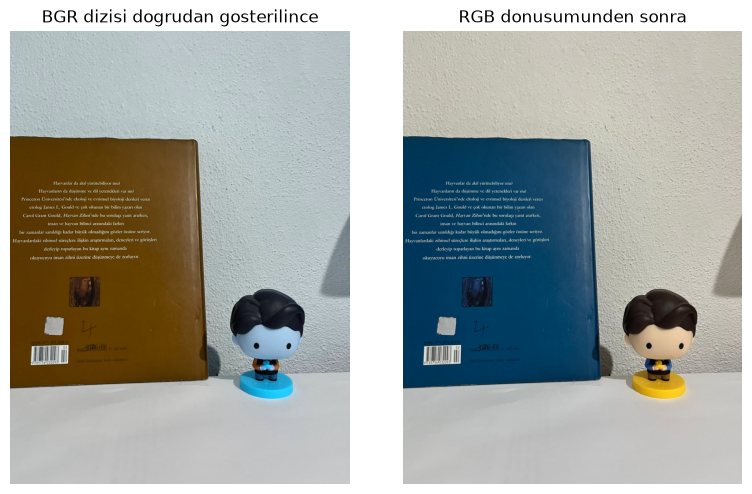

In [24]:
bgr_fotograflar = {}
rgb_fotograflar = {}

for kosul, yol in fotograflar.items():
    bgr = cv2.imread(str(yol))

    if bgr is None:
        raise ValueError(f"fotograf okunmadi: {yol}")
    
    bgr_fotograflar[kosul] = bgr
    rgb_fotograflar[kosul] = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

normal = rgb_fotograflar["normal"]

print("Boyut (height, width, channels):", normal.shape)
print("Veri tipi:", normal.dtype)
print("Gozlemlenen deger araligi:", normal.min(), "ile", normal.max())

fig, eksenler = plt.subplots(1, 2, figsize=(8, 5))

eksenler[0].imshow(bgr_fotograflar["normal"])
eksenler[0].set_title("BGR dizisi dogrudan gosterilince")

eksenler[1].imshow(normal)
eksenler[1].set_title("RGB donusumunden sonra")

for eksen in eksenler:
    eksen.axis("off")

plt.tight_layout()
plt.savefig("outputs/1.png", dpi=300)
plt.show()


In [25]:
noktalar = [(850,1267), (902,1282), (961, 1273)]

for numara, (x, y) in enumerate(noktalar, start = 1):
    print(f"\nNokta {numara} (x= {x}, y={y})")
    
    for kosul, img in rgb_fotograflar.items():
        r,g,b = img[y, x]
        print(f"{kosul:6} R={r:3}, G={g:3}, B={b:3}")

x,y = noktalar[0]

print("\n Ilk noktanin kirmizi kanalini iki diziden okuyalim:")
print("BGR  dizisinde R:", bgr_fotograflar["normal"][y, x, 2])
print("RGB  dizisinde R:", rgb_fotograflar["normal"][y, x, 0]) 



Nokta 1 (x= 850, y=1267)
normal R=203, G=154, B= 13
golge  R=173, G=133, B= 11
lamba  R=200, G=142, B= 32

Nokta 2 (x= 902, y=1282)
normal R=243, G=192, B= 21
golge  R=189, G=145, B= 10
lamba  R=227, G=164, B= 23

Nokta 3 (x= 961, y=1273)
normal R=254, G=208, B= 37
golge  R=193, G=149, B= 26
lamba  R=254, G=201, B= 27

 Ilk noktanin kirmizi kanalini iki diziden okuyalim:
BGR  dizisinde R: 203
RGB  dizisinde R: 203


**Ölçüm sonrası**

Tahminim üç noktada da tuttu. Normal ışıkta kırmızı ve yeşil değerleri maviden yüksekti. Mesela ikinci noktada kırmızı 243’ten 189’a, yeşil de 192’den 145’e düştü. Bunun nedeni gölgede kaideye daha az ışık gelmesi olabilir. Bunu kontrol etmek için aynı çekimi pozlama ve beyaz dengesi sabitken tekrarlayabilirim.

## RGB ve HSV renk eşikleri

**Deney öncesi tahminim**

Gölgede iki maskenin de küçüleceğini ama HSV maskesinin daha az değişeceğini düşünüyorum. Çünkü gölgede parlaklık düşse bile sarının tonu benzer kalabilir.

RGB alt sinir: [180, 132, 0]
RGB ust sinir: [255, 217, 54]
HSV alt sinir: [20, 195, 180]
HSV ust sinir: [25, 255, 255]


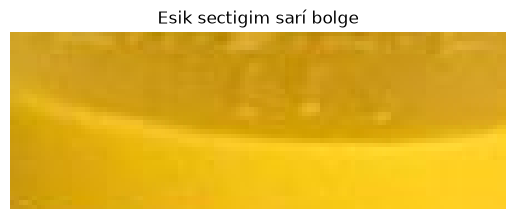

In [26]:
x, y = 850, 1243
genislik, yukseklik = 112, 40

sari_kesit = normal [y:y + yukseklik, x:x + genislik]
hsv_kesit = cv2.cvtColor(sari_kesit, cv2.COLOR_RGB2HSV)

rgb_alt = sari_kesit.min(axis=(0,1)).tolist()
rgb_ust = sari_kesit.max(axis=(0,1)).tolist()

hsv_alt = hsv_kesit.min(axis=(0,1)).tolist()
hsv_ust = hsv_kesit.max(axis=(0,1)).tolist()

print("RGB alt sinir:", rgb_alt)
print("RGB ust sinir:", rgb_ust)
print("HSV alt sinir:", hsv_alt)
print("HSV ust sinir:", hsv_ust)

plt.imshow(sari_kesit)
plt.title("Esik sectigim sarí bolge")
plt.axis("off")
plt.savefig("outputs/2.png")
plt.show()



normal RGB: 10861 / 1920000 (%0.566)
normal HSV: 10731 / 1920000 (%0.559)
golge  RGB:  3472 / 1920000 (%0.181)
golge  HSV:  3470 / 1920000 (%0.181)
lamba  RGB:  9259 / 1920000 (%0.482)
lamba  HSV:  9101 / 1920000 (%0.474)


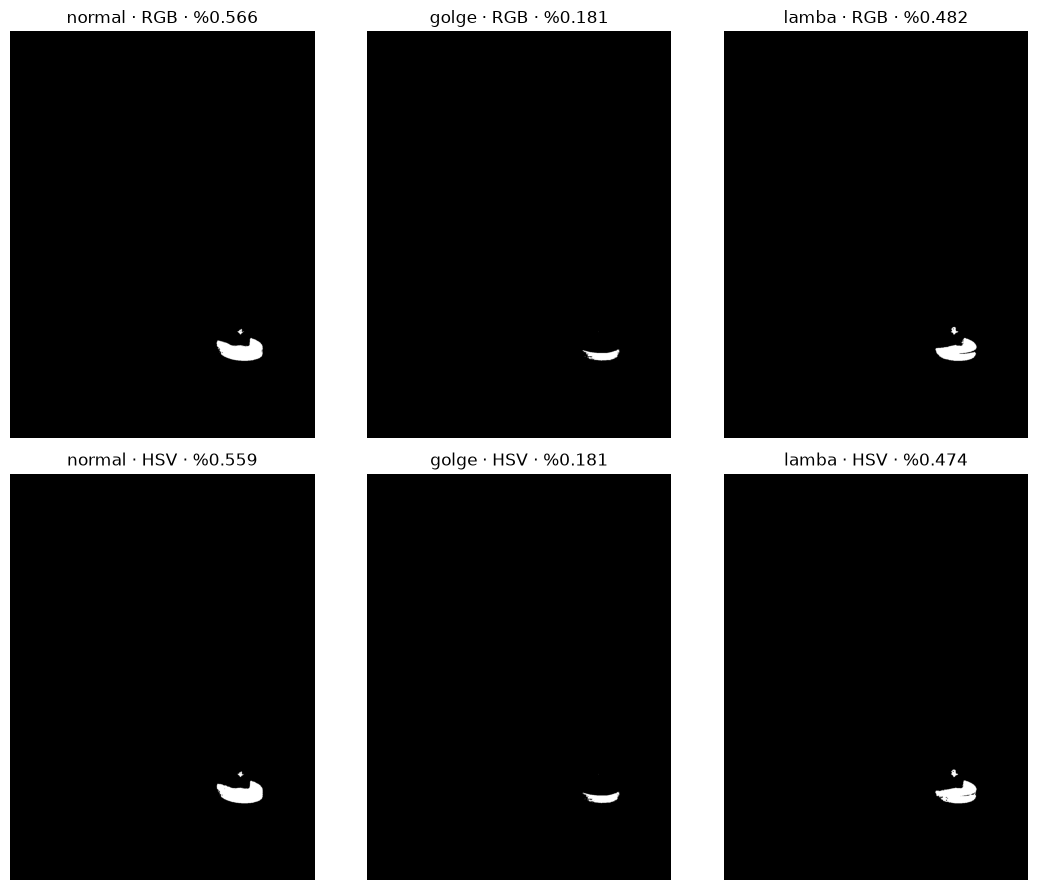

In [27]:
fig, eksenler = plt.subplots(2, 3, figsize=(11, 9))
maske_sonuclari = []

for sutun, (kosul, rgb) in enumerate(rgb_fotograflar.items()):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

    rgb_maske = cv2.inRange(rgb, tuple(rgb_alt), tuple(rgb_ust))
    hsv_maske = cv2.inRange(hsv, tuple(hsv_alt), tuple(hsv_ust))

    for satir, (renk_uzayi, maske) in enumerate([
        ("RGB", rgb_maske),
        ("HSV", hsv_maske),
    ]):
        secilen = np.count_nonzero(maske)
        toplam = maske.size
        yuzde = 100 * secilen / toplam

        maske_sonuclari.append((kosul, renk_uzayi, secilen, toplam, yuzde))
        print(f"{kosul:6} {renk_uzayi}: {secilen:5} / {toplam} (%{yuzde:.3f})")

        eksen = eksenler[satir, sutun]
        eksen.imshow(maske, cmap="gray", vmin=0, vmax=255)
        eksen.set_title(f"{kosul} · {renk_uzayi} · %{yuzde:.3f}")
        eksen.axis("off")

plt.tight_layout()
plt.savefig("outputs/3.png", dpi=300)
plt.show()


**Ölçüm sonrası**

Gölgede RGB maskesi %0,566’dan, HSV maskesi %0,559’dan yaklaşık %0,181’e düştü. İki maskenin de küçülmesini bekliyordum ama HSV’nin daha az etkileneceği tahminim pek tutmadı. Gölgede kaidenin bazı yerleri HSV’deki parlaklık sınırının altında kaldı.

## Parlaklık ve gama

**Parlaklık +40:** Fotoğrafın ortalamasının yaklaşık 40 artacağını düşünüyorum. Çok açık yerlerde bazı değerler 255’i geçeceği için artış biraz daha az olabilir.

**Gama 0,5:** Fotoğrafın ortalamasının artmasını ve gölgeli yerlerin biraz açılmasını bekliyorum. Çünkü gama 0,5 ara tonların değerini yükseltiyor.

**Gama 2,0:** Fotoğrafın ortalamasının düşmesini ve mavi kitap kapağının daha koyu görünmesini bekliyorum. Çünkü gama 2,0 ara tonların değerini düşürüyor.

In [28]:
def parlaklik_ayarla(img, artis):
    img_float = img.astype(np.float32)
    return np.clip(img_float + artis, 0, 255)


def gama_ayarla(img, gama):
    img_float = img.astype(np.float32) / 255
    return np.clip(255 * img_float ** gama, 0, 255)


parlak = parlaklik_ayarla(normal, 40)
gama_05 = gama_ayarla(normal, 0.5)
gama_20 = gama_ayarla(normal, 2.0)

print(f"Normal ortalama: {normal.mean():.2f}")
print(f"Parlaklik +40:   {parlak.mean():.2f}")
print(f"Gama 0.5:        {gama_05.mean():.2f}")
print(f"Gama 2.0:        {gama_20.mean():.2f}")

kirpilan = normal.astype(np.float32) + 40 > 255
print("Kirpilan kanal degeri:", np.count_nonzero(kirpilan))
print("En az bir kanali kirpilan piksel:", np.count_nonzero(kirpilan.any(axis=2)))

Normal ortalama: 146.10
Parlaklik +40:   185.96
Gama 0.5:        182.59
Gama 2.0:        101.63
Kirpilan kanal degeri: 56069
En az bir kanali kirpilan piksel: 36687


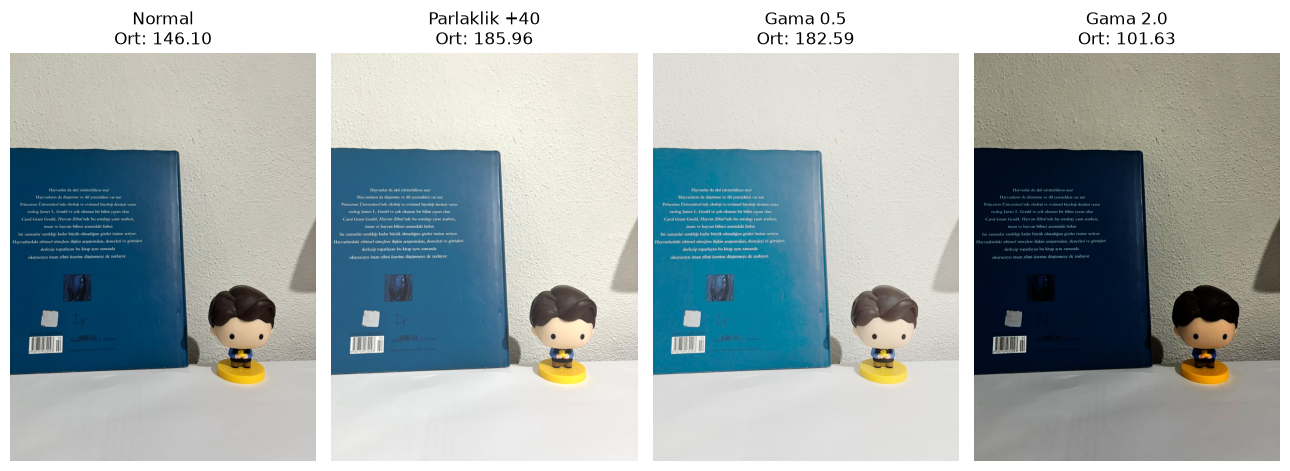

In [29]:
goruntuler = [normal, parlak, gama_05, gama_20]
basliklar = ["Normal", "Parlaklik +40", "Gama 0.5", "Gama 2.0"]

fig, eksenler = plt.subplots(1, 4, figsize=(13, 5))

for eksen, img, baslik in zip(eksenler, goruntuler, basliklar):
    eksen.imshow(np.rint(img).astype(np.uint8))
    eksen.set_title(f"{baslik}\nOrt: {img.mean():.2f}")
    eksen.axis("off")

plt.tight_layout()
plt.savefig("outputs/4.png", dpi=300)
plt.show()



## Küçültme ve büyütme

**En yakın komşu:** Yazıyı dörtte bire küçültüp geri büyütünce bazı harflerin çizgilerinin kopacağını düşünüyorum. Çünkü küçültürken bazı pikseller atlanacak.

**Alan ortalaması:** Yazının daha yumuşak görüneceğini ve biraz daha okunaklı kalacağını tahmin ediyorum. Çünkü harflerin beyaz çizgileri mavi zeminle ortalanacak.

Original size: 572 x 292
Downsampled size: 143 x 73


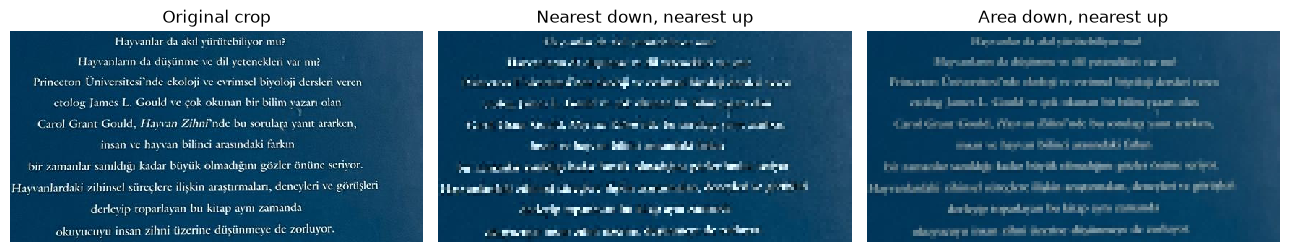

In [30]:
text_crop = normal[524:816, 8:580]
height, width = text_crop.shape[:2]
small_size = (width // 4, height // 4)

small_nearest = cv2.resize(text_crop, small_size, interpolation=cv2.INTER_NEAREST)
small_area = cv2.resize(text_crop, small_size, interpolation=cv2.INTER_AREA)

nearest_back = cv2.resize(small_nearest, (width, height), interpolation=cv2.INTER_NEAREST)
area_back = cv2.resize(small_area, (width, height), interpolation=cv2.INTER_NEAREST)

print(f"Original size: {width} x {height}")
print(f"Downsampled size: {small_size[0]} x {small_size[1]}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
images = [text_crop, nearest_back, area_back]
titles = ["Original crop", "Nearest down, nearest up", "Area down, nearest up"]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig("outputs/5.png", dpi=300)
plt.show()


**Ölçüm sonrası**

Yazı kesiti 572 × 292 pikselden 143 × 73 piksele düştü. En yakın komşuda bazı harf çizgileri koptu. Alan ortalamasında satırlar daha düzgün göründü ama ilk satırdaki küçük harfler yine zor okunuyordu. Büyütme küçük görüntüdeki pikselleri tekrar ettiği için kaybolan çizgiler geri gelmedi.